# 05 Feature Relationship Analysis

The earlier notebooks used anomaly detection to find unusual behavior and supervised classification to predict labelled failures. This notebook investigates a deeper question:

> Does failure depend only on individual sensor values, or also on relationships between sensors?

Instead of only asking:

> Which individual feature is important?

we ask:

> How do features relate to each other, and can combinations of features explain machine behavior better?

The analysis tests four domain-inspired relationship features and compares the same depth-4 decision tree with and without them. This creates a controlled experiment: model settings, split, and target remain fixed while only the feature representation changes.

## Step 1: Import Libraries and Load Dataset

The current AI4I dataset contains **10,000 records and 14 columns**, including 339 failure records. Plotting and correlation are used for exploratory analysis, while a controlled model comparison tests whether the relationships improve prediction.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATA_PATH = '../../data/raw/ai4i2020.csv'

df = pd.read_csv(DATA_PATH)
df.head()

,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Step 2: Select Safe Features

The base feature matrix contains **10,000 rows and six safe input features**:

- `Type`
- `Air temperature`
- `Process temperature`
- `Rotational speed`
- `Torque`
- `Tool wear`

The target failure rate is 3.39%. `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` remain excluded because they are failure-mode labels and would leak target information.

In [2]:
base_features = [
    'Type',
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear',
]

numeric_base_features = [
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear',
]

target = 'Machine failure'

X_base = df[base_features].copy()
y = df[target].copy()

print('Base feature shape:', X_base.shape)
print('Failure rate:', f'{y.mean():.2%}')

Base feature shape: (10000, 6)
Failure rate: 3.39%


## Step 3: Correlation Between Original Numeric Features

Pearson correlation measures the strength and direction of a linear relationship:

$$r_{XY}=\frac{\operatorname{Cov}(X,Y)}{\sigma_X\sigma_Y}$$

A correlation close to `1` means the variables tend to increase together.

A correlation close to `-1` means one tends to increase when the other decreases.

A correlation close to `0` means there is no strong **linear** relationship.

Important limitation:

Correlation does not prove causation and can miss thresholds, curved patterns, and interactions. With a binary target, correlation is equivalent to point-biserial correlation: it measures how the numerical feature differs between the two target groups after accounting for spread.

The original matrix shows two strong sensor relationships: air temperature with process temperature (**r = 0.876**) and rotational speed with torque (**r = -0.875**). These correlations mean the predictors are not independent and may compete for model importance.

In [3]:
original_corr = df[numeric_base_features + [target]].corr().round(3)
original_corr

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
Air temperature,1.000,0.876,0.023,-0.014,0.014,0.083
Process temperature,0.876,1.000,0.019,-0.014,0.013,0.036
Rotational speed,0.023,0.019,1.000,-0.875,0.000,-0.044
Torque,-0.014,-0.014,-0.875,1.000,-0.003,0.191
Tool wear,0.014,0.013,0.000,-0.003,1.000,0.105
Machine failure,0.083,0.036,-0.044,0.191,0.105,1.000


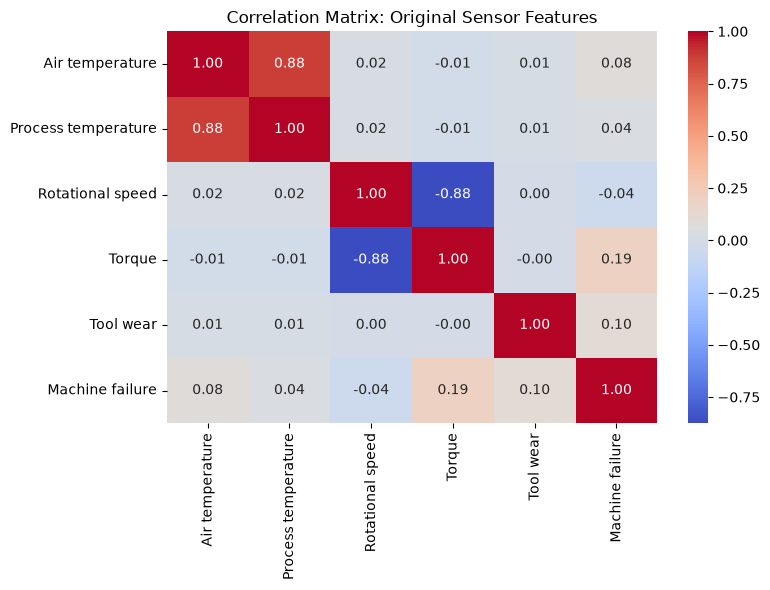

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(original_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix: Original Sensor Features')
plt.tight_layout()
plt.show()

## Step 4: Correlation With Machine Failure

The original feature correlations with `Machine failure` are:

| Feature | Correlation with failure |
|---|---:|
| Torque | 0.191 |
| Tool wear | 0.105 |
| Air temperature | 0.083 |
| Rotational speed | -0.044 |
| Process temperature | 0.036 |

Torque has the strongest individual linear association, but every absolute correlation is below 0.20. A weak marginal correlation does not mean a feature is useless: risk may increase only beyond a threshold or when that feature is combined with another operating condition.

In [5]:
feature_target_corr = (
    original_corr[target]
    .drop(target)
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

feature_target_corr

Torque                 0.191
Tool wear              0.105
Air temperature        0.083
Rotational speed      -0.044
Process temperature    0.036
Name: Machine failure, dtype: float64

## Step 5: Visualize Important Feature Pairs

The previous classifier identified rotational speed, torque, and tool wear as important, so the pair plots examine how failure records occupy the two-dimensional feature space.

So we visualize relationships between:

- rotational speed and torque
- tool wear and torque
- air temperature and process temperature

The speed–torque plot reflects their strong inverse relationship and shows that failures can occur in extreme operating regions rather than along one simple increasing trend. The tool-wear–torque plot tests whether load becomes more consequential as wear accumulates. The temperature plot shows that air and process temperature move together, suggesting that their difference may be more informative than either absolute temperature alone.

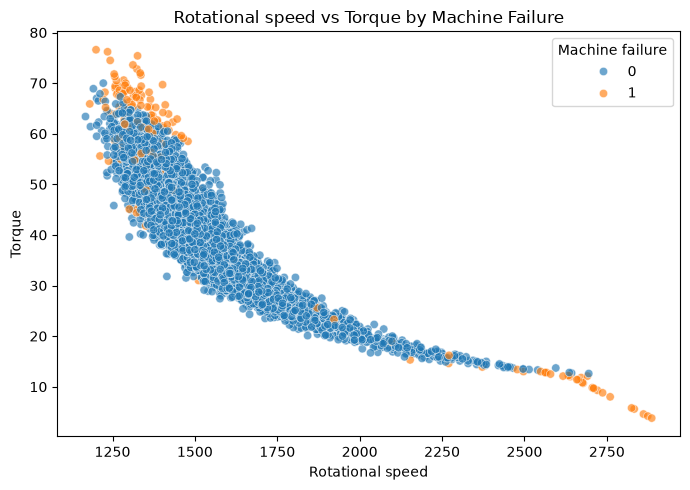

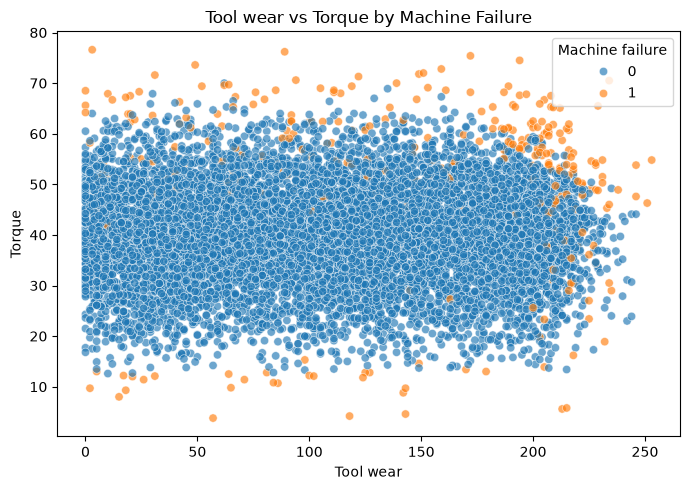

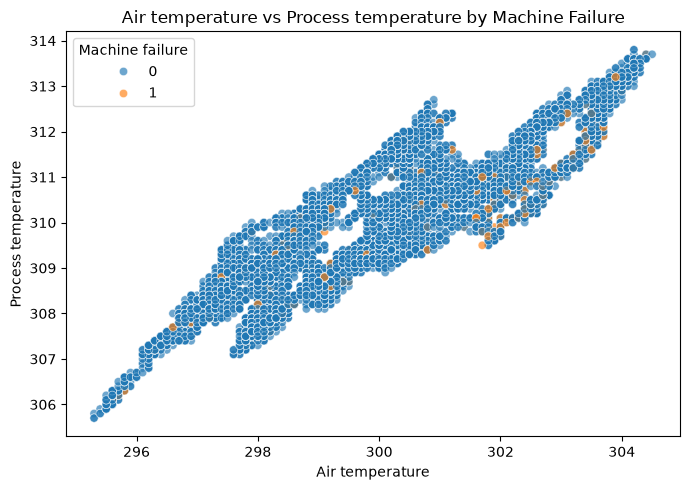

In [6]:
pairs = [
    ('Rotational speed', 'Torque'),
    ('Tool wear', 'Torque'),
    ('Air temperature', 'Process temperature'),
]

for x_feature, y_feature in pairs:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(
        data=df,
        x=x_feature,
        y=y_feature,
        hue=target,
        alpha=0.65
    )
    plt.title(f'{x_feature} vs {y_feature} by Machine Failure')
    plt.tight_layout()
    plt.show()

## Step 6: Create Engineered Relationship Features

Feature engineering converts a hypothesized relationship into a new variable that the model can use directly. These features are calculated independently for each row, so they do not learn information from the test set and do not create preprocessing leakage.

The equations are domain-inspired proxies, not discovered physical laws:

| New Feature | Formula | Meaning |
|---|---|---|
| Temperature difference | $T_{process}-T_{air}$ | Thermal gap between process and environment |
| Power proxy | $Torque \times RPM$ | Proportional to mechanical power/load |
| Wear–torque interaction | $Wear \times Torque$ | Load acting while tool wear accumulates |
| Speed–torque ratio | $RPM/(Torque+\epsilon)$ | Relative speed-to-load operating balance |

Physical rotational power is $P=Torque\times\omega$, where $\omega=RPM\times2\pi/60$. The omitted constant means `Power proxy` is proportional to power rather than measured in watts, which is sufficient for comparing patterns. The small $\epsilon=10^{-6}$ prevents division by zero in the ratio, although ratios can still become unstable when the denominator is small.

The engineered features are hypotheses to test. Predictive improvement would support their usefulness to this model, but would not prove that these equations causally determine failure.

In [7]:
df_engineered = df.copy()

df_engineered['Temperature difference'] = (
    df_engineered['Process temperature'] - df_engineered['Air temperature']
)

df_engineered['Power proxy'] = (
    df_engineered['Torque'] * df_engineered['Rotational speed']
)

df_engineered['Wear torque interaction'] = (
    df_engineered['Tool wear'] * df_engineered['Torque']
)

df_engineered['Speed torque ratio'] = (
    df_engineered['Rotational speed'] / (df_engineered['Torque'] + 1e-6)
)

engineered_features = [
    'Temperature difference',
    'Power proxy',
    'Wear torque interaction',
    'Speed torque ratio',
]

df_engineered[base_features + engineered_features + [target]].head()

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Temperature difference,Power proxy,Wear torque interaction,Speed torque ratio,Machine failure
0,M,298.1,308.6,1551,42.8,0,10.5,66382.8,0.0,36.238317,0
1,L,298.2,308.7,1408,46.3,3,10.5,65190.4,138.9,30.410367,0
2,L,298.1,308.5,1498,49.4,5,10.4,74001.2,247.0,30.323886,0
3,L,298.2,308.6,1433,39.5,7,10.4,56603.5,276.5,36.278480,0
4,L,298.2,308.7,1408,40.0,9,10.5,56320.0,360.0,35.199999,0


## Step 7: Correlation After Adding Engineered Features

The strongest measured linear relationships with failure are torque (**0.191**), wear–torque interaction (**0.190**), power proxy (**0.176**), temperature difference (**-0.112**), and tool wear (**0.105**). The negative temperature-difference correlation means failures tend to occur with a smaller process-to-air thermal gap on average.

The speed–torque ratio has only **0.063** correlation with failure. This weak linear value becomes important later: a feature can have little overall linear association while still separating failures through nonlinear thresholds or extreme regions.

In [8]:
relationship_features = numeric_base_features + engineered_features

engineered_corr = df_engineered[relationship_features + [target]].corr().round(3)
engineered_corr[target].drop(target).sort_values(key=lambda values: values.abs(), ascending=False)

Torque                     0.191
Wear torque interaction    0.190
Power proxy                0.176
Temperature difference    -0.112
Tool wear                  0.105
Air temperature            0.083
Speed torque ratio         0.063
Rotational speed          -0.044
Process temperature        0.036
Name: Machine failure, dtype: float64

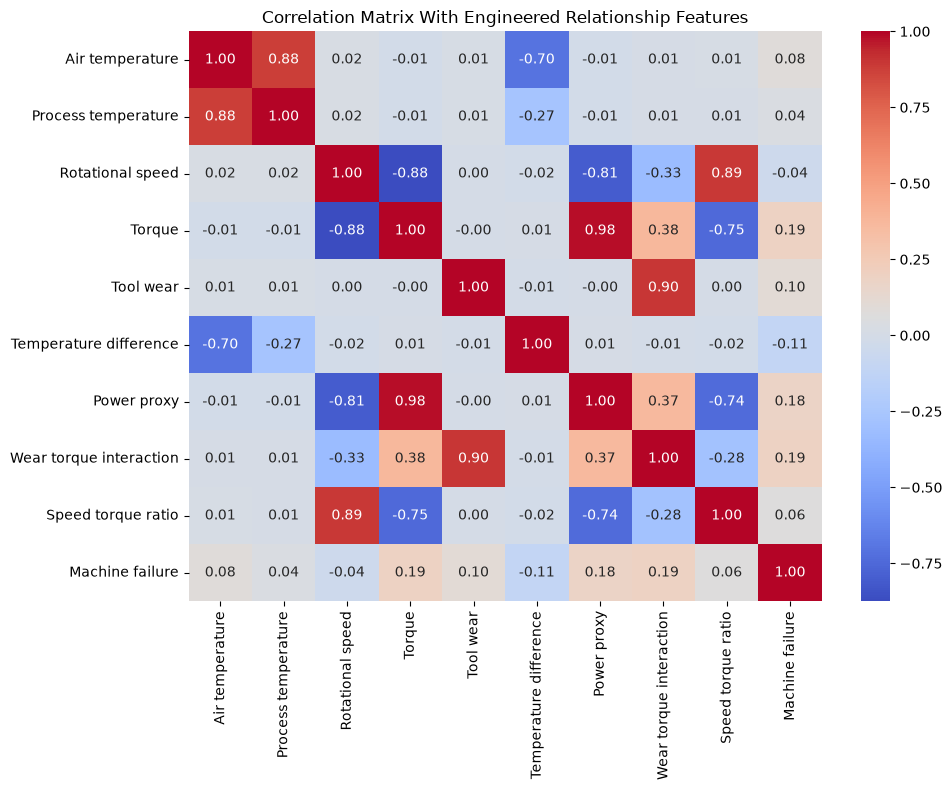

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(engineered_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix With Engineered Relationship Features')
plt.tight_layout()
plt.show()

## Step 8: Compare Base Model vs Engineered Feature Model

We now test whether the engineered features make the classifier more useful. Both models use the same stratified train/test record indices, depth-4 decision tree, balanced class weights, random seed, and evaluation metrics.

We compare two models:

1. Base model: original features only
2. Engineered model: original features + engineered relationship features

This is a controlled feature-ablation experiment: the base model receives the original six features, while the engineered model receives those features plus four relationship variables. Because the split and model configuration are fixed, differences in performance can be attributed to the changed feature representation for this experiment.

In [10]:
def build_model(numeric_features):
    preprocessor = ColumnTransformer(
        transformers=[
            ('numeric', StandardScaler(), numeric_features),
            ('categorical', OneHotEncoder(handle_unknown='ignore'), ['Type']),
        ]
    )

    classifier = DecisionTreeClassifier(
        max_depth=4,
        class_weight='balanced',
        random_state=42
    )

    model = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', classifier),
        ]
    )

    return model


def evaluate_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    cm = confusion_matrix(y_test, predictions)

    return {
        'accuracy': accuracy_score(y_test, predictions),
        'precision': precision_score(y_test, predictions, zero_division=0),
        'recall': recall_score(y_test, predictions, zero_division=0),
        'f1': f1_score(y_test, predictions, zero_division=0),
        'false_positives': cm[0][1],
        'false_negatives': cm[1][0],
        'true_positives': cm[1][1],
        'true_negatives': cm[0][0],
    }

In [11]:
X_engineered = df_engineered[['Type'] + relationship_features].copy()

X_base_train, X_base_test, y_train, y_test = train_test_split(
    X_base,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_eng_train, X_eng_test, _, _ = train_test_split(
    X_engineered,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

base_model = build_model(numeric_base_features)
engineered_model = build_model(relationship_features)

base_metrics = evaluate_model(base_model, X_base_train, X_base_test, y_train, y_test)
engineered_metrics = evaluate_model(engineered_model, X_eng_train, X_eng_test, y_train, y_test)

comparison = pd.DataFrame([
    {'model': 'base_features', **base_metrics},
    {'model': 'base_plus_engineered_features', **engineered_metrics},
])

comparison.round(4)

,model,accuracy,precision,recall,f1,false_positives,false_negatives,true_positives,true_negatives
0,base_features,0.9260,0.3058,0.9265,0.4599,143,5,63,1789
1,base_plus_engineered_features,0.9405,0.3509,0.8824,0.5021,111,8,60,1821


## Step 9: Interpret the Model Comparison

The measured comparison is:

| Model | Accuracy | Precision | Recall | F1 | FP | FN | TP | TN |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Base features | 0.9260 | 0.3058 | 0.9265 | 0.4599 | 143 | 5 | 63 | 1,789 |
| Base + engineered | 0.9405 | 0.3509 | 0.8824 | 0.5021 | 111 | 8 | 60 | 1,821 |

Adding relationship features increases accuracy by 1.45 percentage points, precision by 4.51 points, and F1 by 4.22 points. It removes 32 false alarms but misses three additional failures, reducing recall by 4.41 points.

This is a Responsible AI tradeoff rather than an automatic victory for either model. The preferred model depends on the relative cost of unnecessary maintenance versus an undetected failure. Both error counts must be reported alongside aggregate metrics.

## Step 10: Feature Importance With Engineered Features

Decision-tree importance measures the total weighted impurity reduction produced by splits on each feature. It shows which variables the fitted tree used globally, but not the direction of their effects or the reason for one individual prediction.

The engineered model assigns **34.13%** importance to speed–torque ratio, **31.72%** to power proxy, **15.19%** to tool wear, **10.75%** to temperature difference, and **4.99%** to wear–torque interaction. Rotational speed contributes 3.19%; the remaining variables contribute almost nothing in this particular tree.

The speed–torque ratio is the clearest nonlinearity result: its correlation with failure is only 0.063, yet it is the tree's most-used feature. The tree can split on specific ratio thresholds that Pearson correlation cannot represent. Original torque receiving zero engineered-tree importance does not mean torque is physically irrelevant; its information is also present in the correlated ratio, power, and wear–torque features.

In [11]:
feature_names = engineered_model.named_steps['preprocessor'].get_feature_names_out()
importances = engineered_model.named_steps['classifier'].feature_importances_

engineered_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': importances,
}).sort_values('importance', ascending=False)

engineered_importance

NameError: name 'engineered_model' is not defined

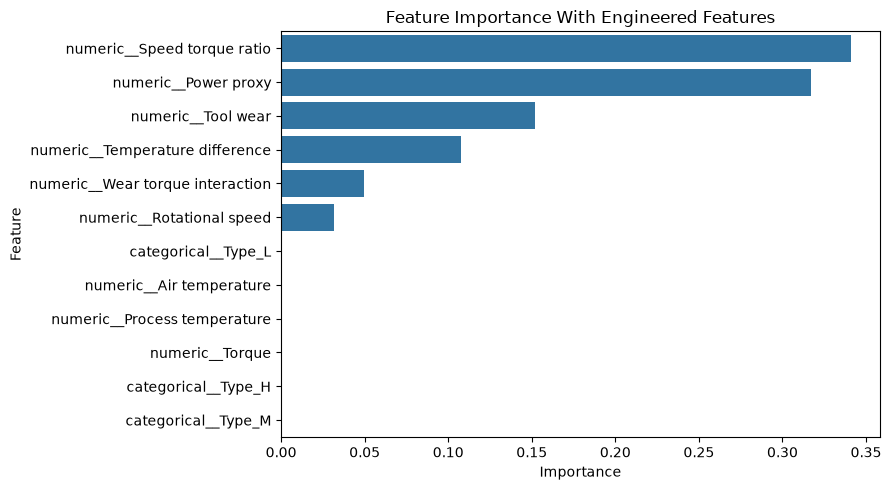

In [13]:
plt.figure(figsize=(9, 5))
sns.barplot(data=engineered_importance, x='importance', y='feature')
plt.title('Feature Importance With Engineered Features')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Step 11: Research Interpretation

The correlation analysis shows that no original sensor has a strong individual linear relationship with failure. Torque has the largest correlation at 0.191, while rotational speed and torque are strongly related to each other at -0.875. These findings support examining operating relationships rather than interpreting each sensor independently.

The engineered decision tree relies mainly on speed–torque ratio and power proxy. This indicates that combinations of speed and load help the shallow tree identify failure-related regions. The contrast between the ratio's weak correlation (0.063) and high model importance (0.341) provides evidence of nonlinear threshold behavior rather than a simple linear trend.

Compared with the base model, engineered features improve precision from 0.3058 to 0.3509 and F1-score from 0.4599 to 0.5021. False positives decrease from 143 to 111. However, recall decreases from 0.9265 to 0.8824, and false negatives increase from five to eight. The engineered model therefore reduces unnecessary alerts at the cost of three additional missed failures.

These results are evidence from one stratified split and one depth-4 decision tree. They do not establish a universal machine equation or causality. The engineered hypotheses should be validated with cross-validation, sensitivity analysis, and explanation methods. Correlated engineered variables can also redistribute tree importance, so importance values should be interpreted as model behavior rather than physical truth.

## Step 12: Save Outputs for Report

The notebook saves the original and engineered correlation matrices, the paired model-comparison table, and engineered feature importances. These files provide traceable numerical evidence for the final report and presentation under `outputs/feature_relationships_from_notebook/`.

In [ ]:
from pathlib import Path

output_dir = Path('../../outputs/feature_relationships_from_notebook')
output_dir.mkdir(parents=True, exist_ok=True)

original_corr.to_csv(output_dir / 'original_feature_correlation.csv')
engineered_corr.to_csv(output_dir / 'engineered_feature_correlation.csv')
comparison.to_csv(output_dir / 'base_vs_engineered_model_metrics.csv', index=False)
engineered_importance.to_csv(output_dir / 'engineered_feature_importance.csv', index=False)

print('Saved outputs to:', output_dir)